## OLCI Sargassum Detection
`Pin pixels by class on a daily SGI zarr and export their values`

### 1. Import Libraries

Needs `ipympl` for clickable figures in Jupyter.

In [6]:
%matplotlib widget

import os
import glob

import numpy as np
import xarray as xr
import pandas as pd
import matplotlib.pyplot as plt

### 2. Paths and parameters

In [7]:
zarr_root = '/home/nandii/olci_sg/day_zarrs'
pins_root = '/home/nandii/olci_sg/pins'

# subset to view and pin in (set these to your scene)
lon_min, lon_max = -62, -58
lat_min, lat_max =  12,  16

# pin classes, selected with keys 1, 2, 3 ... in class order
class_names = ['invalid', 'thin_sargassum', 'dense_sargassum']

# display stretch only, does not affect pinned values
vmin, vmax = -10, 0

zarr_paths = sorted(glob.glob(os.path.join(zarr_root, 'SGI_*.zarr')))
zarr_index = -1
print(f"{len(zarr_paths)} daily zarr(s) found")

8 daily zarr(s) found


### 3. Load the next day with valid pixels in the subset

Rerun this cell, then sections 4 and 5, to move to the next day.

In [8]:
# step forward to the next daily zarr with at least one valid pixel in the subset
zarr_index += 1
while zarr_index < len(zarr_paths):
    ds_day = xr.open_zarr(zarr_paths[zarr_index])
    ds_sub = ds_day.sel(lon = slice(lon_min, lon_max), lat = slice(lat_min, lat_max)).load()
    n_valid = int(np.isfinite(ds_sub['SGI_mean']).sum())
    if n_valid > 0:
        break
    zarr_index += 1
else:
    raise StopIteration("No more daily zarrs with valid pixels in the subset")

lon_sub  = ds_sub['lon'].values
lat_sub  = ds_sub['lat'].values
csv_path = os.path.join(pins_root, 'pins_' + os.path.basename(zarr_paths[zarr_index]).replace('.zarr', '.csv'))
print(f"{ds_day.attrs['date']} (zarr {zarr_index + 1} of {len(zarr_paths)}): "
      f"subset {lat_sub.size} x {lon_sub.size} pixels, {n_valid} valid")

Task was destroyed but it is pending!
task: <Task pending name='Task-807' coro=<_async_in_context.<locals>.run_in_context() done, defined at /home/nandii/.conda/envs/cloudf/lib/python3.11/site-packages/ipykernel/utils.py:57> wait_for=<Task pending name='Task-808' coro=<Kernel.shell_main() running at /home/nandii/.conda/envs/cloudf/lib/python3.11/site-packages/ipykernel/kernelbase.py:597> cb=[Task.task_wakeup()]> cb=[ZMQStream._run_callback.<locals>._log_error() at /home/nandii/.conda/envs/cloudf/lib/python3.11/site-packages/zmq/eventloop/zmqstream.py:563]>
/home/nandii/.conda/envs/cloudf/lib/python3.11/asyncio/base_events.py:782: RuntimeWarning: coroutine 'Kernel.shell_main' was never awaited
  handle = events.Handle(callback, args, self, context)
Task was destroyed but it is pending!
task: <Task pending name='Task-808' coro=<Kernel.shell_main() running at /home/nandii/.conda/envs/cloudf/lib/python3.11/site-packages/ipykernel/kernelbase.py:597> cb=[Task.task_wakeup()]>


2016-05-02 (zarr 2 of 8): subset 1484 x 1484 pixels, 2064057 valid


### 4. Pin pixels

Click a pixel to pin it to the active class. Keys `1`, `2`, `3` switch class; `u` removes the last pin. Turn off zoom/pan before pinning.

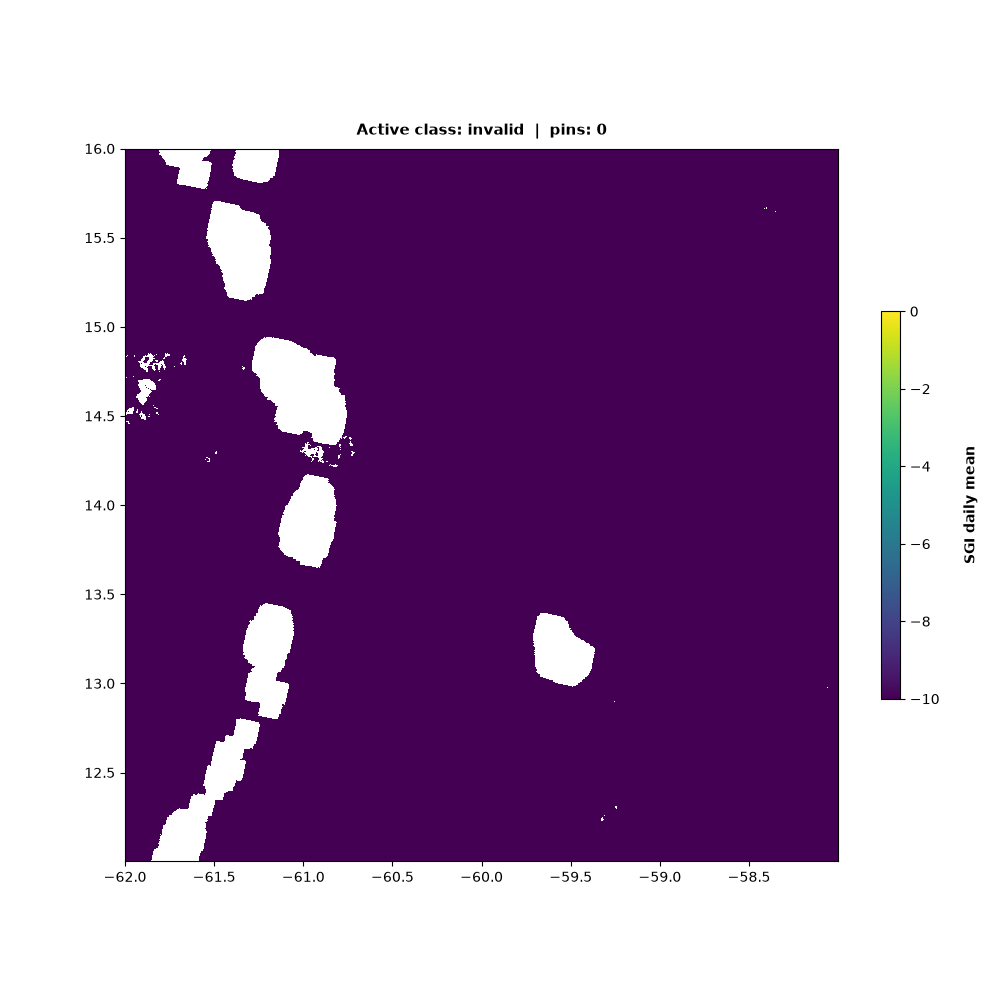

In [9]:
pins    = []
markers = []
active  = {'class': class_names[0]}

# extent from pixel edges, so each grid cell draws centred on its lon/lat
res    = lon_sub[1] - lon_sub[0]
extent = [lon_sub[0] - res / 2, lon_sub[-1] + res / 2, lat_sub[0] - res / 2, lat_sub[-1] + res / 2]

fig, ax = plt.subplots(figsize = (10, 10))
im = ax.imshow(ds_sub['SGI_mean'].values, origin = 'lower', extent = extent,
               cmap = plt.cm.viridis, interpolation = 'nearest')
im.set_clim(vmin, vmax)
cbar = plt.colorbar(im, orientation = "vertical", fraction = 0.025, pad = 0.055)
cbar.set_label(f"\nSGI daily mean", fontsize = 10, weight = 'bold')
ax.set_title(f"Active class: {active['class']}  |  pins: 0", fontsize = 11, weight = 'bold', pad = 10)

def on_click(event):
    # ignore clicks outside the map or while zoom/pan is active
    toolbar = fig.canvas.toolbar
    if event.inaxes is not ax or event.button != 1 or (toolbar is not None and toolbar.mode):
        return

    # snap the click to the nearest grid cell
    pixel = ds_sub.sel(lon = event.xdata, lat = event.ydata, method = 'nearest')
    pins.append({
        'lon'      : float(pixel['lon']),
        'lat'      : float(pixel['lat']),
        'SGI_mean' : float(pixel['SGI_mean']),
        'n_obs'    : int(pixel['n_obs']),
        'class'    : active['class']})

    colour = plt.cm.tab10(class_names.index(active['class']))
    markers.extend(ax.plot(pins[-1]['lon'], pins[-1]['lat'], marker = 'o', markerfacecolor = 'none',
                           markeredgecolor = colour, markersize = 6))
    ax.set_title(f"Active class: {active['class']}  |  pins: {len(pins)}", fontsize = 11, weight = 'bold', pad = 10)
    fig.canvas.draw_idle()

def on_key(event):
    # number keys switch class, u removes the last pin
    if event.key in [str(i + 1) for i in range(len(class_names))]:
        active['class'] = class_names[int(event.key) - 1]
    elif event.key == 'u' and pins:
        pins.pop()
        markers.pop().remove()
    ax.set_title(f"Active class: {active['class']}  |  pins: {len(pins)}", fontsize = 11, weight = 'bold', pad = 10)
    fig.canvas.draw_idle()

fig.canvas.mpl_connect('button_press_event', on_click)
fig.canvas.mpl_connect('key_press_event', on_key)
plt.show()

### 5. Save pins to CSV

In [ ]:
df_pins = pd.DataFrame(pins)
df_pins['date'] = ds_day.attrs['date']

os.makedirs(os.path.dirname(csv_path), exist_ok = True)
df_pins.to_csv(csv_path, index = False)

print(f"Saved {len(df_pins)} pins to {csv_path}")
print(df_pins['class'].value_counts())